# Lesotho POI data: exploratory analysis and cleaning for a GNN

**Input:** `points_of_interest.csv`, the HOT/OpenStreetMap export for Lesotho (snapshot 2026-09-08, 12,536 features, ODbL).
**Output:** `processed_poi.csv`, one cleaned row per POI node, with labels, node features and spatial CV folds.

The GNN planned in the proposal is semi-supervised node classification: each POI is a node, the target is its
amenity category, and `Uncategorized` POIs are unlabelled nodes. Edges (spatial k-NN, district hierarchy, thematic)
are built from this table in the modelling notebook. This notebook answers the questions that design depends on:

1. What does the raw export contain, and which columns carry information?
2. Which rows are duplicates, placeholders or mapping artefacts that would distort the graph?
3. How should raw OSM tags roll up into category labels, and how imbalanced are they?
4. How far apart are POIs, and what does that mean for `k` in the k-NN graph?
5. Do neighbouring POIs share categories (the signal a GNN uses)?
6. Where is mapping effort uneven, and which features would leak the label?

Only the POI export is used; no outside data are added.

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import wkt
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

RAW_CSV = "points_of_interest.csv"
OUT_CSV = "processed_poi.csv"
CRS_GEO = "EPSG:4326"
CRS_M = "EPSG:32735"  # UTM 35S, metres; Lesotho sits inside this zone
SEED = 42

# Chart styling: light surface, recessive hairline grid, one hue per series
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "figure.dpi": 100, "legend.frameon": False,
})
print("pandas", pd.__version__, "| geopandas", gpd.__version__)

pandas 3.0.3 | geopandas 1.1.4


## 1. Raw data and column profile

In [2]:
raw = pd.read_csv(RAW_CSV, dtype=str, encoding="utf-8-sig", keep_default_na=False, na_values=[""])
for c in ["longitude", "latitude"]:
    raw[c] = pd.to_numeric(raw[c])
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns | ids unique: {raw['id'].is_unique}")

profile = pd.DataFrame({
    "non_null": raw.notna().sum(),
    "null_%": (raw.isna().mean() * 100).round(1),
    "distinct": raw.nunique(),
    "example": raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None).astype(str).str[:40],
})
profile

12,536 rows x 31 columns | ids unique: True


,non_null,null_%,distinct,example
id,12536,0.0,12536,way/273358203
name,4248,66.1,3064,Pheellong Primary School
name_en,132,98.9,128,MRU 171
name_st,1,100.0,1,Pelo e Tlotlehang
amenity,8572,31.6,81,toilets
man_made,2243,82.1,41,survey_point
shop,1446,88.5,70,alcohol
tourism,297,97.6,16,hotel
opening_hours,289,97.7,151,Mo-Su 08:30-15:00
beds,0,100.0,0,NaN


In [3]:
raw["osm_type"] = raw["id"].str.split("/").str[0]
raw["osm_num"] = raw["id"].str.split("/").str[1].astype("int64")
print(pd.crosstab(raw["osm_type"], raw["geometry_type"], margins=True), "\n")

geom = gpd.GeoSeries(raw["geometry_wkt"].map(wkt.loads), crs=CRS_GEO)
pt = gpd.GeoSeries(gpd.points_from_xy(raw["longitude"], raw["latitude"]), crs=CRS_GEO)
geom_m, pt_m = geom.to_crs(CRS_M), pt.to_crs(CRS_M)

# Is the supplied lon/lat the centroid of the geometry, and does it fall inside the shape?
off = pt_m.distance(geom_m.centroid)
inside = geom_m.buffer(0.01).contains(pt_m)
chk = pd.DataFrame({"type": raw["geometry_type"], "m_from_centroid": off, "point_inside": inside})
print(chk.groupby("type").agg(n=("point_inside", "size"),
                              median_m_from_centroid=("m_from_centroid", "median"),
                              max_m_from_centroid=("m_from_centroid", "max"),
                              share_inside=("point_inside", "mean")).round(3), "\n")

area = geom_m.area.where(raw["geometry_type"].eq("Polygon"))
length = geom_m.length.where(raw["geometry_type"].eq("LineString"))
print("Polygon area (m2):\n", area.describe(percentiles=[.5, .9, .99]).round(0).to_string(), "\n")
print("LineString length (m):\n", length.describe(percentiles=[.5, .9, .99]).round(0).to_string(), "\n")
print("Lines by tag:", raw.loc[raw["geometry_type"].eq("LineString"), ["amenity", "man_made", "shop", "tourism"]]
      .stack().value_counts().head(8).to_dict())
print("lon range", raw["longitude"].min(), raw["longitude"].max(), "| lat range", raw["latitude"].min(), raw["latitude"].max())

geometry_type  LineString  Point  Polygon    All
osm_type                                        
node                    0   5372        0   5372
relation                0      0        2      2
way                   284      0     6878   7162
All                   284   5372     6880  12536 



               n  median_m_from_centroid  max_m_from_centroid  share_inside
type                                                                       
LineString   284                   0.018               52.246         0.359
Point       5372                   0.000                0.000         1.000
Polygon     6880                   0.004                0.013         0.996 

Polygon area (m2):
 count       6880.0
mean        6246.0
std        36861.0
min            0.0
50%           53.0
90%        16166.0
99%        77213.0
max      2114398.0 

LineString length (m):
 count      284.0
mean       717.0
std       3797.0
min          1.0
50%         32.0
90%        466.0
99%      16717.0
max      43699.0 

Lines by tag: {'kraal': 83, 'pipeline': 71, 'goods_conveyor': 57, 'embankment': 34, 'geoglyph': 30, 'pier': 7, 'proposed': 1, 'symbol': 1}
lon range 27.0421278 29.3128778 | lat range -30.6165857 -28.5287418


In [4]:
KEYS = ["amenity", "shop", "tourism", "man_made"]
for k in KEYS:
    raw[k] = raw[k].str.strip().str.lower()

n_keys = raw[KEYS].notna().sum(axis=1)
print("Tag keys per row:", n_keys.value_counts().sort_index().to_dict())
combo = raw[KEYS].notna().apply(lambda r: "+".join(k for k in KEYS if r[k]) or "(none)", axis=1)
print("Key combinations:", combo.value_counts().to_dict(), "\n")
print("Multi-key examples:")
print(raw.loc[n_keys > 1, ["name"] + KEYS].head(12).to_string(), "\n")

for k in KEYS:
    vc = raw[k].value_counts()
    print(f"{k}: {len(vc)} values | top: {vc.head(12).to_dict()}")
    rare = vc[vc <= 2]
    print(f"   {len(rare)} values used <= 2 times: {', '.join(rare.index[:25])}{' ...' if len(rare) > 25 else ''}\n")

Tag keys per row: {1: 12514, 2: 22}
Key combinations: {'amenity': 8553, 'man_made': 2234, 'shop': 1434, 'tourism': 293, 'amenity+shop': 10, 'amenity+man_made': 8, 'shop+tourism': 2, 'amenity+tourism': 1, 'tourism+man_made': 1} 

Multi-key examples:
                              name         amenity         shop tourism   man_made
2858                           NaN  drinking_water          NaN     NaN  water_tap
3240         Shell Filling Station            fuel  convenience     NaN        NaN
3303                           NaN     water_point          NaN     NaN  water_tap
3304                           NaN     water_point          NaN     NaN  water_tap
3305                           NaN     water_point          NaN     NaN  water_tap
3335                      watertap     water_point          NaN     NaN  water_tap
6660  Lower-Moyeni Filling Station            fuel          yes     NaN        NaN
6764                           NaN             bar  convenience     NaN        NaN
6932

In [5]:
no_admin = raw["adm1_pcode"].isna()
print("Rows without a district:")
print(raw.loc[no_admin, ["id", "name", "amenity", "shop", "man_made", "tourism", "longitude", "latitude"]].to_string(), "\n")

# Distance from that row to the nearest POI that does have a district
xy_m = np.c_[pt_m.x, pt_m.y]
d, j = cKDTree(xy_m[~no_admin]).query(xy_m[no_admin])
print(f"Nearest POI with a district is {d[0]:,.0f} m away, in {raw.loc[~no_admin].iloc[j[0]]['adm1_name']}\n")

dist = (raw.groupby(["adm1_pcode", "adm1_name"]).agg(pois=("id", "size"), sub_districts=("adm2_pcode", "nunique"))
        .sort_values("pois", ascending=False))
dist["share_%"] = (dist["pois"] / dist["pois"].sum() * 100).round(1)
print(dist.to_string())
per_adm2 = raw.groupby("adm2_pcode").size()
print(f"\nPOIs per sub-district: min {per_adm2.min()}, median {per_adm2.median():.0f}, max {per_adm2.max()} "
      f"({per_adm2.idxmax()}); sub-districts with < 20 POIs: {(per_adm2 < 20).sum()}")

Rows without a district:
                  id                   name amenity shop  man_made tourism  longitude   latitude
7106  way/1280995428  Delivery Tunnel North     NaN  NaN  pipeline     NaN  28.425275 -28.528742 

Nearest POI with a district is 10,067 m away, in Butha-Buthe

                          pois  sub_districts  share_%
adm1_pcode adm1_name                                  
LSE        Mafeteng       2870              8     22.9
LSA        Maseru         2834             12     22.6
LSC        Leribe         1467             14     11.7
LSD        Berea          1360             10     10.8
LSJ        Mokhotlong      956              5      7.6
LSK        Thaba-Tseka     927              6      7.4
LSF        Mohale's Hoek   644              9      5.1
LSH        Qacha's Nek     546              4      4.4
LSG        Quthing         474              6      3.8
LSB        Butha-Buthe     457              5      3.6

POIs per sub-district: min 9, median 102, max 1489 (LSA1

### Toilets: the largest tag
`amenity=toilets` is 36% of the raw export. Before treating each toilet as a node, check where they were mapped and what they are.

Toilets: 4,473 | polygons 53% | named 0.1% | median footprint 9 m2
Toilets within 150 m of a school: 4% | median distance to the next toilet: 45 m



               toilets  other_pois  toilet_share_%
adm1_name                                         
Quthing             16         458             3.0
Butha-Buthe         24         433             5.0
Maseru             283        2551            10.0
Qacha's Nek        122         424            22.0
Mohale's Hoek      174         470            27.0
Mokhotlong         266         690            28.0
Leribe             460        1007            31.0
Berea              468         892            34.0
Thaba-Tseka        363         564            39.0
Mafeteng          2297         573            80.0

Mafeteng holds 51% of all toilets but 7% of other POIs
Toilet way ids, 5th-95th percentile: [273181507 437000137 560739381]


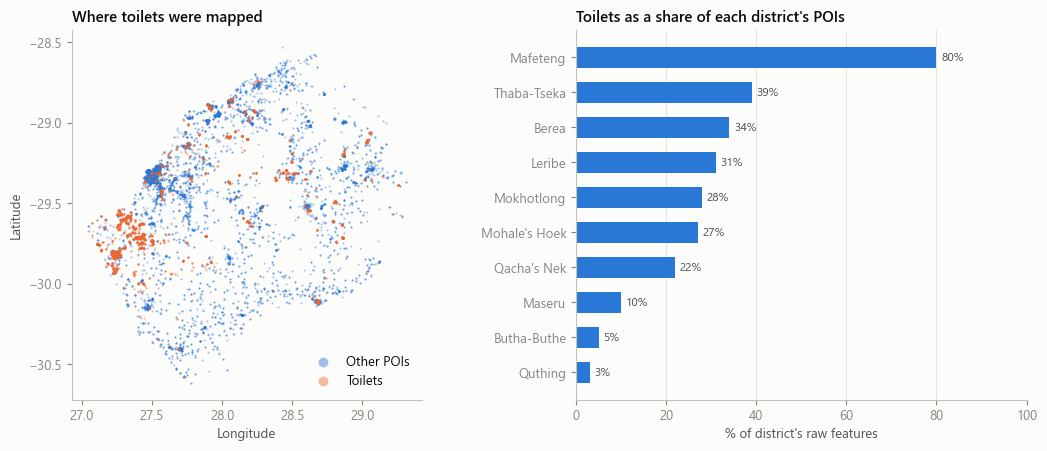

In [6]:
is_toilet = raw["amenity"].eq("toilets")
is_school = raw["amenity"].eq("school")
t = raw[is_toilet]
print(f"Toilets: {is_toilet.sum():,} | polygons {t['geometry_type'].eq('Polygon').mean():.0%} | "
      f"named {t['name'].notna().mean():.1%} | median footprint {area[is_toilet].median():.0f} m2")

d_school, _ = cKDTree(xy_m[is_school]).query(xy_m[is_toilet])
d_toilet, _ = cKDTree(xy_m[is_toilet]).query(xy_m[is_toilet], k=2)
print(f"Toilets within 150 m of a school: {(d_school <= 150).mean():.0%} | "
      f"median distance to the next toilet: {np.median(d_toilet[:, 1]):.0f} m\n")

by_d = pd.DataFrame({"toilets": raw[is_toilet].groupby("adm1_name").size(),
                     "other_pois": raw[~is_toilet].groupby("adm1_name").size()}).fillna(0).astype(int)
by_d["toilet_share_%"] = (by_d["toilets"] / (by_d["toilets"] + by_d["other_pois"]) * 100).round(0)
by_d = by_d.sort_values("toilet_share_%")
print(by_d.to_string())
print(f"\nMafeteng holds {by_d.loc['Mafeteng', 'toilets'] / by_d['toilets'].sum():.0%} of all toilets "
      f"but {by_d.loc['Mafeteng', 'other_pois'] / by_d['other_pois'].sum():.0%} of other POIs")

# OSM ids are issued in sequence, so the id shows when a feature was first mapped
t_way = raw[is_toilet & raw["osm_type"].eq("way")]
print("Toilet way ids, 5th-95th percentile:", np.percentile(t_way["osm_num"], [5, 50, 95]).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
ax.scatter(raw.loc[~is_toilet, "longitude"], raw.loc[~is_toilet, "latitude"], s=2, c=BLUE, alpha=.45, lw=0, label="Other POIs")
ax.scatter(raw.loc[is_toilet, "longitude"], raw.loc[is_toilet, "latitude"], s=2, c=ORANGE, alpha=.45, lw=0, label="Toilets")
ax.set_aspect(1 / np.cos(np.deg2rad(29.5))); ax.grid(False)
ax.set_title("Where toilets were mapped"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend(markerscale=5, loc="lower right")
ax = axes[1]
ax.barh(by_d.index, by_d["toilet_share_%"], color=BLUE, height=.6)
for y, v in enumerate(by_d["toilet_share_%"]):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", color=INK2, fontsize=8.5)
ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_title("Toilets as a share of each district's POIs"); ax.set_xlabel("% of district's raw features")
plt.tight_layout(); plt.show()

**Finding.** The toilets are household pit latrines rather than public facilities: 9 m² median footprint, almost none named,
only 4% within 150 m of a school, and typically 45 m from the next latrine (house-to-house spacing). Half of them come
from one mapping effort in Mafeteng, where they make up 80% of all features. As graph nodes they would make Mafeteng's
villages look like dense clusters of "Infrastructure" and would dominate that class. They do carry a useful signal (where
households are), so they are kept out of the node set and turned into a per-node feature: latrine count within 1 km.

## 2. From OSM tags to category labels

Each feature takes its label from one tag. For the 22 features with two keys, `tourism` wins over `amenity`, which wins
over `shop`, then `man_made` (for example a fuel station that is also tagged `shop=convenience` is a fuel station; a
lodge tagged `amenity=restaurant` and `tourism=hotel` is accommodation). Raw values roll up into about 35 subcategories
and then into the 8 categories used in the proposal. `man_made=yes` and `amenity=fixme` say nothing about the feature,
so they become `Uncategorized` (unlabelled nodes). Some features are removed instead of labelled:

- **Placeholders:** `shop=vacant` and `man_made=proposed` (the feature has closed or does not exist yet). The two
  `shop=no` tags sit on camp sites and mean "no shop on site"; `tourism` takes precedence, so those rows are kept.
- **Linear networks:** `pipeline`, `goods_conveyor`, `embankment`. These are lines up to 44 km long; their centroid is
  not a place, and one of them (a water-transfer tunnel) has its centroid outside Lesotho.

In [7]:
SUBCATEGORY_TAGS = {
    # Retail
    "Small grocery": {"shop": ["kiosk", "convenience", "general", "variety_store", "greengrocer", "deli", "farm"]},
    "Supermarket & wholesale": {"shop": ["supermarket", "wholesale", "department_store", "mall"]},
    "Clothing & personal care": {"shop": ["clothes", "shoes", "bag", "hairdresser", "beauty", "cosmetics",
                                          "dry_cleaning", "laundry"]},
    "Automotive & fuel": {"amenity": ["fuel", "car_wash", "car_rental", "vehicle_inspection"],
                          "shop": ["car_repair", "car", "car_parts", "tyres", "bicycle", "fuel"],
                          "man_made": ["fuel_pump"]},
    "Hardware & home": {"shop": ["hardware", "doityourself", "furniture", "kitchen", "household", "houseware",
                                 "interior_decoration", "electrical", "garden_centre", "agrarian", "trade", "gas"]},
    "Electronics & phones": {"shop": ["mobile_phone", "electronics", "computer", "hifi", "call", "photo", "copyshop"]},
    "Alcohol": {"shop": ["alcohol", "beverages"]},
    "Butcher & bakery": {"shop": ["butcher", "bakery", "seafood", "flour_mill"]},
    "Funeral services": {"shop": ["funeral_directors"], "amenity": ["mortuary"]},
    "Market": {"amenity": ["marketplace"]},
    "Other retail": {"shop": ["yes", "books", "stationery", "gift", "toys", "florist", "art", "craft", "collector",
                              "sports", "outdoor", "optician"]},
    # Food & Beverage
    "Bar & nightlife": {"amenity": ["bar", "pub", "nightclub", "casino", "gambling"]},
    "Restaurant & cafe": {"amenity": ["restaurant", "cafe"], "shop": ["coffee"]},
    "Fast food": {"amenity": ["fast_food", "food_court"]},
    # Tourism
    "Accommodation": {"tourism": ["guest_house", "hotel", "chalet", "hostel", "apartment", "motel", "camp_site",
                                  "alpine_hut"]},
    "Attraction & information": {"tourism": ["viewpoint", "attraction", "information", "artwork", "museum",
                                             "picnic_site", "ground_sign", "yes"]},
    # Educational
    "School": {"amenity": ["school", "prep_school"]},
    "Pre-school & childcare": {"amenity": ["kindergarten", "childcare"]},
    "Tertiary & training": {"amenity": ["college", "university", "language_school", "driving_school"]},
    # Healthcare
    "Clinic & hospital": {"amenity": ["clinic", "hospital", "doctors", "dentist"]},
    "Pharmacy": {"amenity": ["pharmacy"], "shop": ["chemist", "medical_supply"]},
    # Religious
    "Place of worship": {"amenity": ["place_of_worship", "monastery"], "man_made": ["cross"]},
    "Cemetery": {"amenity": ["grave_yard"]},
    # Other (services and public institutions)
    "Finance": {"amenity": ["bank", "atm", "bureau_de_change"], "shop": ["money_lender"]},
    "Post office": {"amenity": ["post_office", "post_box"]},
    "Public admin & safety": {"amenity": ["police", "courthouse", "townhall", "prison", "fire_station",
                                          "ranger_station", "security_booth", "reception_desk"]},
    "Community & leisure": {"amenity": ["community_centre", "social_facility", "library", "events_venue",
                                        "conference_centre", "arts_centre", "theatre", "stage", "planetarium",
                                        "studio", "give_box"]},
    "Other services": {"amenity": ["veterinary", "animal_shelter", "brothel"], "shop": ["travel_agency"]},
    # Infrastructure
    "Transport & parking": {"amenity": ["parking", "parking_space", "taxi", "bus_station", "ferry_terminal",
                                        "boat_storage", "bicycle_rental", "bicycle_repair_station", "weighbridge",
                                        "shelter"],
                            "man_made": ["pier", "bridge"]},
    "Sanitation & waste": {"amenity": ["toilets", "waste_disposal", "sanitary_dump_station", "waste_basket",
                                       "recycling"],
                           "man_made": ["wastewater_plant", "manhole", "septic_tank"]},
    "Water supply": {"amenity": ["water_point", "drinking_water", "fountain"],
                     "man_made": ["storage_tank", "water_tower", "water_works", "water_well", "water_tap",
                                  "reservoir_covered", "pumping_station", "water_pump", "windmill"]},
    "Telecom & power": {"amenity": ["telephone"],
                        "man_made": ["mast", "tower", "antenna", "satellite_dish", "street_cabinet", "utility_pole"]},
    "Agriculture": {"man_made": ["kraal", "silo", "bunker_silo", "animal_dip"]},
    "Industry & mining": {"amenity": ["warehouse"], "man_made": ["works", "adit", "tailings_pond", "chimney"]},
    "Minor structures": {"amenity": ["bench", "hunting_stand"],
                         "man_made": ["survey_point", "flagpole", "geoglyph", "symbol", "advertising",
                                      "monitoring_station"]},
    "Unspecified": {"amenity": ["fixme"], "man_made": ["yes"]},
}
SUB_TO_CAT = {}
for cat, subs in {
    "Retail": ["Small grocery", "Supermarket & wholesale", "Clothing & personal care", "Automotive & fuel",
               "Hardware & home", "Electronics & phones", "Alcohol", "Butcher & bakery", "Funeral services",
               "Market", "Other retail"],
    "Food & Beverage": ["Bar & nightlife", "Restaurant & cafe", "Fast food"],
    "Tourism": ["Accommodation", "Attraction & information"],
    "Educational": ["School", "Pre-school & childcare", "Tertiary & training"],
    "Healthcare": ["Clinic & hospital", "Pharmacy"],
    "Religious": ["Place of worship", "Cemetery"],
    "Other": ["Finance", "Post office", "Public admin & safety", "Community & leisure", "Other services"],
    "Infrastructure": ["Transport & parking", "Sanitation & waste", "Water supply", "Telecom & power",
                       "Agriculture", "Industry & mining", "Minor structures"],
    "Uncategorized": ["Unspecified"],
}.items():
    SUB_TO_CAT.update({s: cat for s in subs})
# Subcategories that are private businesses (the "business insight" subset)
BUSINESS_SUBS = [s for s, c in SUB_TO_CAT.items() if c in ("Retail", "Food & Beverage")] + \
                ["Accommodation", "Finance", "Other services"]
DROP_TAGS = {("shop", "no"): "placeholder", ("shop", "vacant"): "placeholder", ("man_made", "proposed"): "placeholder",
             ("man_made", "pipeline"): "linear network", ("man_made", "goods_conveyor"): "linear network",
             ("man_made", "embankment"): "linear network"}

TAG_TO_SUB = {(k, v): sub for sub, kv in SUBCATEGORY_TAGS.items() for k, vals in kv.items() for v in vals}
assert len(TAG_TO_SUB) == sum(len(v) for kv in SUBCATEGORY_TAGS.values() for v in kv.values()), "a tag is mapped twice"
assert set(SUB_TO_CAT) == set(SUBCATEGORY_TAGS)

PRECEDENCE = ["tourism", "amenity", "shop", "man_made"]
def primary_tag(row):
    for k in PRECEDENCE:
        if pd.notna(row[k]):
            return k, row[k]

raw[["tag_key", "tag_value"]] = pd.DataFrame(raw.apply(primary_tag, axis=1).tolist(), index=raw.index)
raw["drop_reason"] = [DROP_TAGS.get(kv) for kv in zip(raw["tag_key"], raw["tag_value"])]
raw["subcategory"] = [TAG_TO_SUB.get(kv) for kv in zip(raw["tag_key"], raw["tag_value"])]
raw["category"] = raw["subcategory"].map(SUB_TO_CAT)

unmapped = raw[raw["subcategory"].isna() & raw["drop_reason"].isna()]
assert unmapped.empty, unmapped[["tag_key", "tag_value"]].value_counts()
print(f"{len(TAG_TO_SUB)} tag values -> {len(SUB_TO_CAT)} subcategories -> {raw['category'].nunique()} categories; "
      f"every raw value is mapped or dropped")
print("To drop:", raw["drop_reason"].value_counts().to_dict(), "|",
      raw.loc[raw["drop_reason"].notna()].groupby(["tag_value", "geometry_type"]).size().to_dict())

202 tag values -> 36 subcategories -> 9 categories; every raw value is mapped or dropped
To drop: {'linear network': 162, 'placeholder': 2} | {('embankment', 'LineString'): 34, ('goods_conveyor', 'LineString'): 57, ('pipeline', 'LineString'): 71, ('proposed', 'LineString'): 1, ('vacant', 'Polygon'): 1}


## 3. Duplicates

OSM often holds one establishment twice: as a point (a node with the name) and as a building outline (a way), or as
several outlines of the same compound. Duplicates matter for a GNN beyond double counting: two copies of one place
become each other's nearest neighbour with the same label, so the model looks accurate by copying the label across the
edge. The candidates are pairs of features within 100 m of each other.

In [8]:
keep = raw["drop_reason"].isna() & ~is_toilet
cand = raw[keep].copy()
cand["geom_m"] = geom_m[keep]
cand["x"], cand["y"] = pt_m[keep].x, pt_m[keep].y
cand = cand.reset_index().rename(columns={"index": "raw_row"})

def norm_name(s):
    s = s.fillna(cand["name_en"]).str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip().replace("", np.nan)
cand["name_norm"] = norm_name(cand["name"])

pairs = np.array(sorted(cKDTree(cand[["x", "y"]].to_numpy()).query_pairs(100)))
a, b = cand.iloc[pairs[:, 0]].reset_index(drop=True), cand.iloc[pairs[:, 1]].reset_index(drop=True)
P = pd.DataFrame({"i": pairs[:, 0], "j": pairs[:, 1],
                  "dist_m": np.hypot(a["x"] - b["x"], a["y"] - b["y"]).to_numpy()})
P["same_name"] = (a["name_norm"] == b["name_norm"]).to_numpy()
P["same_sub"] = (a["subcategory"] == b["subcategory"]).to_numpy()
P["same_cat"] = (a["category"] == b["category"]).to_numpy()
P["point_way"] = (a["osm_type"].eq("node") ^ b["osm_type"].eq("node")).to_numpy()
ga, gb = gpd.GeoSeries(a["geom_m"].to_numpy()), gpd.GeoSeries(b["geom_m"].to_numpy())
P["touching"] = (ga.buffer(1).intersects(gb)).to_numpy()   # overlapping, containing or within 1 m
P["both_unnamed"] = (a["name_norm"].isna() & b["name_norm"].isna()).to_numpy()

print(f"{len(cand):,} candidate nodes (toilets and dropped tags removed); {len(P):,} pairs within 100 m\n")
summary = pd.Series({
    "same name, same category": (P["same_name"] & P["same_cat"]).sum(),
    "  ...of which point + outline": (P["same_name"] & P["same_cat"] & P["point_way"]).sum(),
    "same name, different category": (P["same_name"] & ~P["same_cat"]).sum(),
    "touching, same subcategory, not both named differently": (P["touching"] & P["same_sub"] & ~(~P["same_name"] & ~P["both_unnamed"] & a["name_norm"].notna().to_numpy() & b["name_norm"].notna().to_numpy())).sum(),
    "unnamed, same subcategory, < 50 m": (P["both_unnamed"] & P["same_sub"] & (P["dist_m"] < 50)).sum(),
})
print(summary.to_string(), "\n")
show = ["name", "tag_value", "category", "geometry_type"]
ex = P[P["same_name"] & ~P["same_cat"]].head(6)
print("Same name, different category (kept apart):")
print(pd.concat([a.loc[ex.index, show].add_suffix("_a").reset_index(drop=True),
                 b.loc[ex.index, show].add_suffix("_b").reset_index(drop=True)], axis=1).to_string())

7,899 candidate nodes (toilets and dropped tags removed); 15,384 pairs within 100 m

same name, same category                                   750
  ...of which point + outline                              706
same name, different category                                4
touching, same subcategory, not both named differently     360
unnamed, same subcategory, < 50 m                         3904 

Same name, different category (kept apart):
           name_a tag_value_a category_a geometry_type_a          name_b tag_value_b       category_b geometry_type_b
0        Sparrows        fuel     Retail           Point        Sparrows  restaurant  Food & Beverage           Point
1         Capital     alcohol     Retail           Point         Capital   fast_food  Food & Beverage           Point
2  Malealea Lodge      hostel    Tourism         Polygon  Malealea Lodge  restaurant  Food & Beverage           Point
3      Clan Lodge       hotel    Tourism           Point      Clan lodge  restaura

In [9]:
close = P[P["both_unnamed"] & P["same_sub"] & (P["dist_m"] < 50)]
by_sub = (pd.DataFrame({"subcategory": a.loc[close.index, "subcategory"], "tag": a.loc[close.index, "tag_value"]})
          .value_counts().rename("pairs").reset_index())
n_sub = cand.groupby("subcategory").size()
by_sub["features_of_this_sub"] = by_sub["subcategory"].map(n_sub)
print("Unnamed same-subcategory pairs < 50 m apart, by tag:")
print(by_sub.head(15).to_string(index=False), "\n")

# What do clusters of repeated units look like? Link unnamed same-subcategory features < 50 m apart
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
def components(n, edges):
    m = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])), shape=(n, n))
    return connected_components(m, directed=False)[1]
comp = components(len(cand), close[["i", "j"]].to_numpy())
sizes = pd.Series(comp).value_counts()
grp = cand.assign(comp=comp).groupby("comp")
span = grp.apply(lambda g: np.hypot(g["x"].max() - g["x"].min(), g["y"].max() - g["y"].min()), include_groups=False)
multi = sizes[sizes > 1].index
print(f"{len(multi):,} clusters hold {sizes[multi].sum():,} features; size median {sizes[multi].median():.0f}, "
      f"max {sizes.max()}; diagonal span median {span[multi].median():.0f} m, 95th pct {span[multi].quantile(.95):.0f} m, "
      f"max {span[multi].max():.0f} m")
big = span[multi].sort_values().tail(5).index
print(cand.assign(comp=comp)[cand.assign(comp=comp)["comp"].isin(big)].groupby("comp")
      .agg(n=("id", "size"), tag=("tag_value", "first"), district=("adm1_name", "first")).assign(span_m=span[big].round(0)).to_string())

Unnamed same-subcategory pairs < 50 m apart, by tag:
        subcategory          tag  pairs  features_of_this_sub
      Small grocery        kiosk   1794                   614
       Water supply storage_tank    720                   589
   Minor structures     geoglyph    181                   344
Community & leisure     give_box    163                    88
        Agriculture         silo    140                   214
      Accommodation  guest_house    113                   217
      Small grocery      general    102                   614
        Agriculture  bunker_silo     87                   214
        Unspecified          yes     76                   193
        Agriculture        kraal     68                   214
Transport & parking      parking     65                   418
    Telecom & power         mast     50                   528
      Small grocery  convenience     49                   614
 Sanitation & waste      manhole     39                   169
       Other reta

373 clusters hold 1,423 features; size median 2, max 70; diagonal span median 30 m, 95th pct 87 m, max 331 m
       n           tag    district  span_m
comp                                      
1907  19  storage_tank      Maseru   173.0
2885  33         kiosk  Mokhotlong   243.0
3684  22         kiosk     Quthing   149.0
5566  33         kiosk    Mafeteng   201.0
6539  70         kiosk      Maseru   331.0


**Findings.** Three patterns account for nearly all near-duplicates:

- **A. Same establishment, mapped twice.** 750 pairs share a name and a category within 100 m; 706 of them are a point
  plus a building outline. The four same-name pairs with different categories are real separate facilities (a lodge
  and its restaurant, a fuel station and a restaurant of the same brand), so category must match too.
- **B. Unnamed point inside or touching an outline of the same type** (a school point dropped inside the school
  polygon). Same subcategory, geometries within 1 m, and no conflicting names.
- **C. Repeated units of one site.** Unnamed features of the same subcategory within 50 m: storage tanks at one water
  works, silos on one farm, letters of one hillside geoglyph, parking bays of one car park, and kiosk stalls in a
  market (313 kiosks, 98% of them 12 m² stall outlines, 96% in clusters, concentrated in Semonkong and Mafeteng).
  Kept separate, one market becomes 70 near-identical nodes that are each other's neighbours.

All three rules link features; linked groups become one node placed at the members' mean position. The group size is
kept as `n_units` so that the intensity of a market or tank farm is not lost. Because `n_units` is computed from the
labels (only same-type features are grouped), it must not be used as a model feature.

In [10]:
both_named = (a["name_norm"].notna() & b["name_norm"].notna()).to_numpy()
rule_a = P["same_name"] & P["same_cat"] & both_named
rule_b = P["touching"] & P["same_sub"] & ~(both_named & ~P["same_name"])
rule_c = P["both_unnamed"] & P["same_sub"] & (P["dist_m"] < 50)
print("Pairs linked by rule A:", rule_a.sum(), "| B:", rule_b.sum(), "| C:", rule_c.sum(),
      "| any:", (rule_a | rule_b | rule_c).sum())
top_names = a.loc[rule_a[rule_a].index, "name"].value_counts().head(8)
print("Most frequent names among rule-A pairs:", top_names.to_dict())
print("Features named 'Pig':", cand.loc[cand["name"].eq("Pig"), ["tag_value", "adm2_name"]].value_counts().to_dict())

cand["group"] = components(len(cand), P.loc[rule_a | rule_b | rule_c, ["i", "j"]].to_numpy())
cand["area_m2"] = gpd.GeoSeries(cand["geom_m"]).area.where(cand["geometry_type"].eq("Polygon"), 0.0)
# Representative member: a named point carries the richest tags, then a named outline, then the largest outline
cand["_rank"] = (cand["name_norm"].isna() * 2 + cand["osm_type"].ne("node")) * 1e12 - cand["area_m2"]
first = lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan
g = cand.sort_values("_rank").groupby("group", sort=False)
TAGS = ["name", "name_en", "amenity", "shop", "tourism", "man_made", "tag_key", "tag_value", "subcategory",
        "category", "adm1_pcode", "adm1_name", "adm2_pcode", "adm2_name"]
poi = g[TAGS].first()  # the representative's tags
poi["id"] = g["id"].first()
poi["name"] = g["name"].agg(first)
poi["osm_ids"] = g["id"].agg(lambda s: ";".join(s))
poi["n_units"] = g.size()
poi["x"], poi["y"] = g["x"].mean(), g["y"].mean()
poi["footprint_m2"] = g["area_m2"].max()
poi["opening_hours"] = g["opening_hours"].agg(first)
poi["addr_street"], poi["addr_city"], poi["addr_housenumber"] = (g[c].agg(first) for c in
                                                                 ["addr_street", "addr_city", "addr_housenumber"])
poi["has_point"] = g["osm_type"].agg(lambda s: s.eq("node").any())
poi["has_outline"] = g["geometry_type"].agg(lambda s: s.eq("Polygon").any())
poi["osm_num_min"] = g["osm_num"].min()
poi = poi.reset_index(drop=True)

sub_changed = (g["subcategory"].nunique() > 1).sum()
print(f"\n{len(cand):,} features -> {len(poi):,} nodes ({len(cand) - len(poi):,} merged away); "
      f"{(poi['n_units'] > 1).sum():,} nodes are merged groups; groups mixing subcategories: {sub_changed}")
print("n_units distribution:", poi["n_units"].value_counts().sort_index().pipe(
    lambda s: {**s.head(5).to_dict(), ">5": int(s[s.index > 5].sum())}))

# Check: no two nodes left that rule A would still join
t2 = cKDTree(poi[["x", "y"]].to_numpy())
nn = pd.DataFrame(sorted(t2.query_pairs(100)), columns=["i", "j"])
nm = poi["name"].pipe(lambda s: s.str.lower().str.replace(r"[^a-z0-9]", "", regex=True))
left = nn[(nm[nn.i].to_numpy() == nm[nn.j].to_numpy()) & nm[nn.i].notna().to_numpy()
          & (poi["category"][nn.i].to_numpy() == poi["category"][nn.j].to_numpy())]
print("Same-name, same-category pairs still within 100 m:", len(left))

Pairs linked by rule A: 750 | B: 360 | C: 3904 | any: 4686
Most frequent names among rule-A pairs: {'Pig': 21, 'Standard Lesotho Bank': 3, 'Puma': 3, 'Nedbank': 3, 'Bolahla Primary School': 2, 'Liphakoeng Primary School': 2, 'Kokobe Primary School': 2, 'New Millennium English Medium': 2}
Features named 'Pig': {('animal_shelter', 'Qiloane'): 7}



7,899 features -> 6,083 nodes (1,816 merged away); 1,129 nodes are merged groups; groups mixing subcategories: 5
n_units distribution: {1: 4954, 2: 969, 3: 67, 4: 31, 5: 10, '>5': 52}
Same-name, same-category pairs still within 100 m: 0


## 4. Labels after cleaning

                                                          step  rows_after  removed
                                                    Raw export       12536        0
            Drop placeholders (shop=vacant, man_made=proposed)       12534        2
   Drop linear networks (pipeline, goods_conveyor, embankment)       12372      162
Move household latrines (amenity=toilets) to a context feature        7899     4473
           Merge duplicates and repeated units (rules A, B, C)        6083     1816 

                 nodes  share_%  class_weight
category                                     
Infrastructure    1792     29.5          0.42
Educational       1666     27.4          0.45
Retail            1181     19.4          0.63
Other              334      5.5          2.23
Food & Beverage    293      4.8          2.54
Tourism            252      4.1          2.95
Religious          236      3.9          3.15
Healthcare         198      3.3          3.76
Uncategorized      131      2.2   

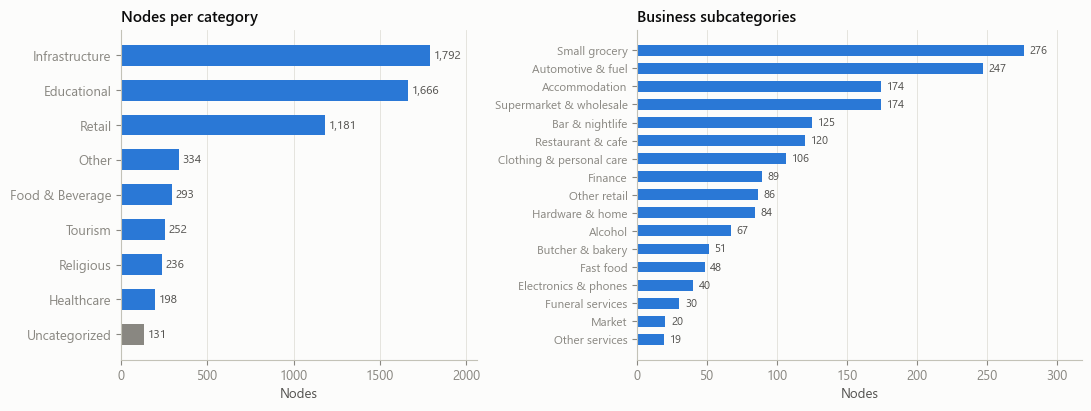

In [11]:
n_raw = len(raw)
n_place = n_raw - raw["drop_reason"].eq("placeholder").sum()
n_line = n_place - raw["drop_reason"].eq("linear network").sum()
n_toil = n_line - (is_toilet & raw["drop_reason"].isna()).sum()
cleaning_log = pd.DataFrame([
    ("Raw export", n_raw),
    ("Drop placeholders (shop=vacant, man_made=proposed)", n_place),
    ("Drop linear networks (pipeline, goods_conveyor, embankment)", n_line),
    ("Move household latrines (amenity=toilets) to a context feature", n_toil),
    ("Merge duplicates and repeated units (rules A, B, C)", len(poi)),
], columns=["step", "rows_after"])
cleaning_log["removed"] = -cleaning_log["rows_after"].diff().fillna(0).astype(int)
print(cleaning_log.to_string(index=False), "\n")

CATS = ["Infrastructure", "Educational", "Retail", "Other", "Food & Beverage", "Tourism", "Religious", "Healthcare"]
labelled = poi["category"].ne("Uncategorized")
counts = poi["category"].value_counts()
lab = counts[CATS]
dist_tbl = pd.DataFrame({"nodes": counts, "share_%": (counts / len(poi) * 100).round(1)})
dist_tbl["class_weight"] = (labelled.sum() / (len(CATS) * lab)).round(2)  # sklearn "balanced"
print(dist_tbl.to_string(), "\n")
print(f"Labelled {labelled.sum():,} | unlabelled {(~labelled).sum():,} | "
      f"largest/smallest class ratio {lab.max() / lab.min():.1f}x")

subs = poi.groupby(["category", "subcategory"]).size().rename("nodes").reset_index()
subs["business"] = subs["subcategory"].isin(BUSINESS_SUBS)
print(f"\nSubcategories with < 15 nodes: {(subs['nodes'] < 15).sum()} of {len(subs)} -> "
      f"{', '.join(subs.loc[subs['nodes'] < 15, 'subcategory'])}")
print(f"Business nodes: {poi['subcategory'].isin(BUSINESS_SUBS).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
s = counts.sort_values()
ax.barh(s.index, s.values, color=[MUTED if i == "Uncategorized" else BLUE for i in s.index], height=.6)
for y, v in enumerate(s.values):
    ax.text(v + 20, y, f"{v:,}", va="center", color=INK2, fontsize=8.5)
ax.set_title("Nodes per category"); ax.set_xlabel("Nodes"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, s.max() * 1.15)
ax = axes[1]
b = subs[subs["business"]].sort_values("nodes")
ax.barh(b["subcategory"], b["nodes"], color=BLUE, height=.6)
for y, v in enumerate(b["nodes"]):
    ax.text(v + 4, y, f"{v:,}", va="center", color=INK2, fontsize=8)
ax.set_title("Business subcategories"); ax.set_xlabel("Nodes"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5); ax.set_xlim(0, b["nodes"].max() * 1.15)
plt.tight_layout(); plt.show()

**Findings.** After cleaning, 6,083 nodes remain, 5,952 of them labelled. The largest class (Infrastructure) is 9.1 times
the smallest (Healthcare), so the loss needs the class weights above and evaluation needs macro-F1. Only 131 nodes are
`Uncategorized`; the proposal's figure of 1,471 unlabelled nodes came from an earlier processing and should be updated.

## 5. Spatial structure: choosing the graph

The export has no edges, so the graph comes from geometry. A fixed-radius graph links POIs closer than *r*; a k-NN graph
links each POI to its *k* nearest. The question is which one keeps rural POIs connected without flooding towns.

Distance to the k-th nearest POI (m):
        25%     50%     75%     90%      max
k=1    48.0   121.0   457.0  1724.0  11953.0
k=3   135.0   372.0  1584.0  3373.0  14030.0
k=5   213.0   585.0  2418.0  4399.0  16797.0
k=8   304.0   839.0  3296.0  5505.0  17778.0
k=10  358.0  1012.0  3794.0  6135.0  18284.0
k=15  503.0  1448.0  4733.0  7475.0  24543.0
k=20  614.0  1853.0  5709.0  8829.0  26893.0 

 radius_m  isolated_%  median_degree
      500        24.0            4.0
     1000        16.4            9.0
     2000         8.4           22.0
     5000         0.5           71.0 

 k  undirected_edges  components  largest_component_%  median_edge_reach_km
 5             19862          10                97.19                  0.59
 8             31452           1               100.00                  0.84
10             39192           1               100.00                  1.01


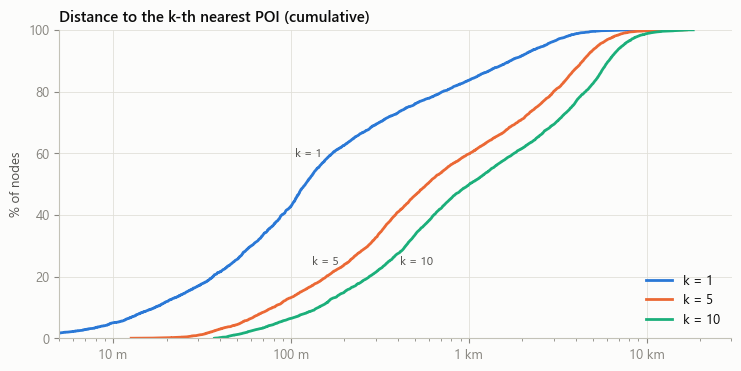

In [12]:
XY = poi[["x", "y"]].to_numpy()
tree = cKDTree(XY)
dk, ik = tree.query(XY, k=21)  # column 0 is the node itself
print("Distance to the k-th nearest POI (m):")
print(pd.DataFrame({f"k={k}": dk[:, k] for k in [1, 3, 5, 8, 10, 15, 20]})
      .describe(percentiles=[.25, .5, .75, .9]).T[["25%", "50%", "75%", "90%", "max"]].round(0).to_string(), "\n")

# Radius graphs: how many nodes have no neighbour at all?
rad = pd.DataFrame([(r, (tree.query_ball_point(XY, r, return_length=True) - 1 == 0).mean() * 100,
                     np.median(tree.query_ball_point(XY, r, return_length=True) - 1)) for r in [500, 1000, 2000, 5000]],
                   columns=["radius_m", "isolated_%", "median_degree"]).round(1)
print(rad.to_string(index=False), "\n")

# k-NN graphs (made symmetric): connectivity and degree
rows = []
for k in [5, 8, 10]:
    src = np.repeat(np.arange(len(XY)), k); dst = ik[:, 1:k + 1].ravel()
    ncomp, lab_c = connected_components(coo_matrix((np.ones(len(src)), (src, dst)), shape=(len(XY),) * 2), directed=False)
    deg = np.bincount(np.r_[src, dst], minlength=len(XY))  # before de-duplicating mutual pairs
    mutual = coo_matrix((np.ones(len(src)), (src, dst)), shape=(len(XY),) * 2)
    und = ((mutual + mutual.T) > 0).sum() // 2
    rows.append((k, und, ncomp, np.bincount(lab_c).max() / len(XY) * 100, np.median(dk[:, k]) / 1000))
print(pd.DataFrame(rows, columns=["k", "undirected_edges", "components", "largest_component_%",
                                  "median_edge_reach_km"]).round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for k, col, y, side in [(1, BLUE, 60, -1), (5, ORANGE, 25, -1), (10, AQUA, 25, 1)]:
    d = np.sort(dk[:, k]); ax.plot(d, np.arange(1, len(d) + 1) / len(d) * 100, color=col, lw=2, label=f"k = {k}")
    ax.annotate(f"k = {k}", (np.percentile(d, y), y), xytext=(8 * side, 0), textcoords="offset points",
                ha="left" if side > 0 else "right", va="center", color=INK2, fontsize=8.5)
ax.set_xscale("log"); ax.set_xlim(5, 3e4); ax.set_ylim(0, 100)
ax.set_xticks([10, 100, 1000, 10000]); ax.set_xticklabels(["10 m", "100 m", "1 km", "10 km"])
ax.set_ylabel("% of nodes"); ax.set_title("Distance to the k-th nearest POI (cumulative)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Findings.** POI spacing is very uneven: half of all nodes have a neighbour within 121 m, but 10% are more than 1.7 km
from any other POI. A radius graph cannot serve both: at 1 km, 16% of nodes have no neighbour; at 5 km, town nodes get
a median of 71. A k-NN graph adapts to density. With k = 5 the graph splits into 10 pieces (2.8% of nodes cut off);
**k = 8 is the smallest value tested that joins every node into one component**, with a median edge of 0.84 km. (The
proposal's statement that the median neighbour distance is 2 to 3 km does not hold for the cleaned data: the median
distance to the nearest POI is 121 m and to the 8th nearest 839 m.)

## 6. Do neighbours share categories?

A GNN helps only if a node's neighbours say something about its own label. Two measures: the share of k-NN edges
that join two nodes of the same category (compared with chance), and how the chance that two POIs share a category
falls with distance.

k=8 edge homophily: 0.39 of edges join same-category nodes (chance 0.22)

                 same_category_neighbours  class_share  lift
Infrastructure                       0.45         0.30  1.49
Educational                          0.47         0.28  1.67
Retail                               0.48         0.20  2.42
Other                                0.14         0.06  2.57
Food & Beverage                      0.14         0.05  2.86
Tourism                              0.20         0.04  4.72
Religious                            0.07         0.04  1.70
Healthcare                           0.04         0.03  1.18 



               p_same_category   pairs
band                                  
[0, 50)                  0.414    2202
[50, 100)                0.422    4017
[100, 250)               0.360   14109
[250, 500)               0.310   29840
[500, 1000)              0.224   65639
[1000, 2000)             0.210  145346
[2000, 5000)             0.235  496938
[5000, 10000)            0.228  608349

Chance level (random pair): 0.218


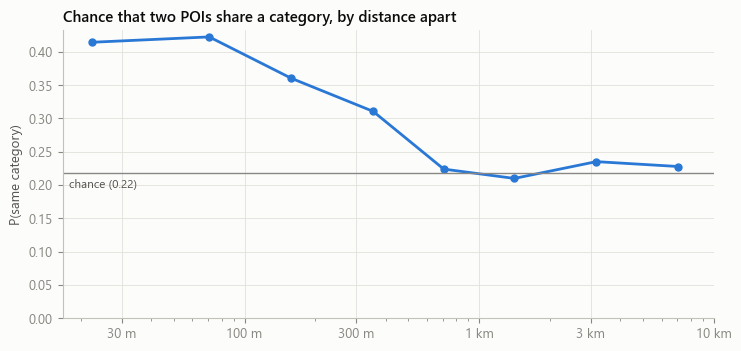

In [13]:
K = 8
cat_arr = poi["category"].to_numpy()
is_lab = labelled.to_numpy()
src = np.repeat(np.arange(len(XY)), K); dst = ik[:, 1:K + 1].ravel()
ok = is_lab[src] & is_lab[dst]
p = poi.loc[labelled, "category"].value_counts(normalize=True)
chance = (p ** 2).sum()
edge_h = (cat_arr[src[ok]] == cat_arr[dst[ok]]).mean()
print(f"k={K} edge homophily: {edge_h:.2f} of edges join same-category nodes (chance {chance:.2f})\n")

per = pd.DataFrame({"src": cat_arr[src[ok]], "same": cat_arr[src[ok]] == cat_arr[dst[ok]]}).groupby("src")["same"].mean()
per_tbl = pd.DataFrame({"same_category_neighbours": per, "class_share": p}).loc[CATS]
per_tbl["lift"] = per_tbl["same_category_neighbours"] / per_tbl["class_share"]
print(per_tbl.round(2).to_string(), "\n")

# Same-category probability by distance band (all labelled pairs within 10 km)
lab_idx = np.flatnonzero(is_lab)
pr = cKDTree(XY[lab_idx]).query_pairs(10_000, output_type="ndarray")
dd = np.hypot(*(XY[lab_idx[pr[:, 0]]] - XY[lab_idx[pr[:, 1]]]).T)
same = cat_arr[lab_idx[pr[:, 0]]] == cat_arr[lab_idx[pr[:, 1]]]
bands = [0, 50, 100, 250, 500, 1000, 2000, 5000, 10000]
band = pd.cut(dd, bands, right=False)
by_band = pd.DataFrame({"band": band, "same": same}).groupby("band", observed=True)["same"].agg(["mean", "size"])
by_band.columns = ["p_same_category", "pairs"]
print(by_band.round(3).to_string())
print(f"\nChance level (random pair): {chance:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
mid = np.sqrt(np.array(bands[:-1]).clip(min=10) * np.array(bands[1:]))
ax.plot(mid, by_band["p_same_category"], color=BLUE, lw=2, marker="o", ms=5)
ax.axhline(chance, color=MUTED, lw=1)
ax.text(0.01, chance - .008, f"chance ({chance:.2f})", transform=ax.get_yaxis_transform(), ha="left", va="top",
        color=INK2, fontsize=8.5)
ax.set_xscale("log"); ax.set_xticks([30, 100, 300, 1000, 3000, 10000])
ax.set_xticklabels(["30 m", "100 m", "300 m", "1 km", "3 km", "10 km"])
ax.set_ylim(0, None); ax.set_ylabel("P(same category)")
ax.set_title("Chance that two POIs share a category, by distance apart")
plt.tight_layout(); plt.show()

**Findings.** 39% of k = 8 edges join two nodes of the same category, against 22% for random pairs. Two POIs within
100 m share a category 42% of the time; the effect fades to chance by about 700 m. Tourism, Food & Beverage, Other and
Retail cluster most (2.4 to 4.7 times their share). Healthcare barely clusters with itself (lift 1.18): clinics sit
among other types, so a clinic's neighbours say "what kind of place this is" rather than "another clinic here". A
model that only averages neighbour labels (plain GCN smoothing) will struggle there; architectures that weigh self and
neighbours separately (GraphSAGE, GAT) and thematic edges that link complementary types should help.

### Which categories locate together? (co-location quotients)
CLQ(A→B) is the share of B among A's 8 nearest neighbours divided by B's share overall; above 1 means B turns up near A
more often than chance. This is the evidence for thematic edges. It uses every label, so it is descriptive only; in the
model, thematic edges must be recomputed from the training fold's labels.

Strongest cross-category attractions (CLQ > 1.3):
              A               B  clq
     Healthcare           Other 1.81
         Retail Food & Beverage 1.81
Food & Beverage          Retail 1.80
          Other      Healthcare 1.62
         Retail           Other 1.49
          Other          Retail 1.48
        Tourism Food & Beverage 1.40
          Other Food & Beverage 1.39
     Healthcare          Retail 1.34
Food & Beverage           Other 1.32


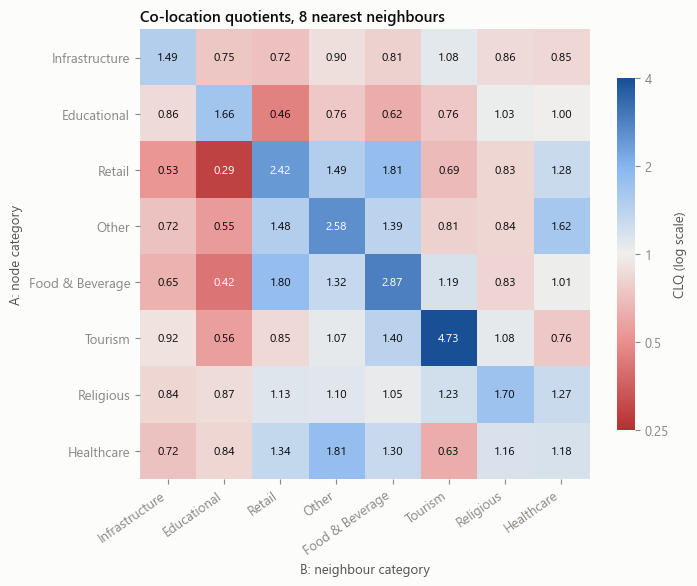

In [14]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

def colocation_quotients(labels, nbr_idx, classes):
    """CLQ(A->B) over k-NN neighbour lists; nodes with a label outside `classes` are ignored."""
    ok = np.isin(labels, classes)
    L, n = labels[ok], ok.sum()
    nb = labels[nbr_idx[ok]]                      # neighbour labels (unlabelled neighbours stay in the count)
    N = pd.Series(L).value_counts().reindex(classes)
    out = pd.DataFrame(index=classes, columns=classes, dtype=float)
    for A in classes:
        frac = (nb[L == A][:, :, None] == np.array(classes)).mean(axis=1).mean(axis=0)
        exp = np.array([(N[B] - (A == B)) / (n - 1) for B in classes])
        out.loc[A] = frac / exp
    return out

clq = colocation_quotients(cat_arr, ik[:, 1:K + 1], CATS)
print("Strongest cross-category attractions (CLQ > 1.3):")
pairs_ = clq.stack().rename("clq").reset_index().rename(columns={"level_0": "A", "level_1": "B"})
print(pairs_[(pairs_["A"] != pairs_["B"]) & (pairs_["clq"] > 1.3)].sort_values("clq", ascending=False)
      .round(2).to_string(index=False))

cmap = LinearSegmentedColormap.from_list("div", ["#b52f2f", "#e98f8e", "#f0efec", "#86b6ef", "#184f95"])
lv = np.log2(clq.astype(float))
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(lv, cmap=cmap, norm=TwoSlopeNorm(0, -2, 2))
for i in range(len(CATS)):
    for j in range(len(CATS)):
        v = clq.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(np.log2(v)) > 1.2 else INK)
ax.set_xticks(range(len(CATS)), CATS, rotation=35, ha="right"); ax.set_yticks(range(len(CATS)), CATS)
ax.set_xlabel("B: neighbour category"); ax.set_ylabel("A: node category"); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=.75, ticks=[-2, -1, 0, 1, 2])
cb.ax.set_yticklabels(["0.25", "0.5", "1", "2", "4"]); cb.set_label("CLQ (log scale)"); cb.outline.set_visible(False)
ax.set_title("Co-location quotients, 8 nearest neighbours")
plt.tight_layout(); plt.show()

**Findings.** The commercial types locate together: Retail, Food & Beverage, Other (banks, police, post, services) and
Healthcare all attract each other (CLQ 1.3 to 1.8), which is the signature of town centres. Educational nodes avoid
Retail (0.29) and Food & Beverage (0.42): schools are spread through villages, shops are concentrated in towns.
Tourism is the most self-clustered type (4.73): lodges, chalets and viewpoints come in groups. Candidate thematic
edges are therefore Retail–Food & Beverage, Retail–Other, Other–Healthcare and Tourism–Food & Beverage.

## 7. Attributes, label leakage and mapping bias

The proposal lists sparse attributes (name, address, hours, footprint) as node features. Two checks: how complete
they are per category, and whether any of them gives the label away.

In [15]:
poi["has_name"] = poi["name"].notna().astype(int)
poi["has_address"] = poi[["addr_street", "addr_city", "addr_housenumber"]].notna().any(axis=1).astype(int)
poi["has_hours"] = poi["opening_hours"].notna().astype(int)
poi["has_footprint"] = (poi["footprint_m2"] > 0).astype(int)
attr = ["has_name", "has_address", "has_hours", "has_footprint"]
comp_tbl = (poi.groupby("category")[attr].mean() * 100).round(0).loc[CATS + ["Uncategorized"]]
comp_tbl.loc["All nodes"] = (poi[attr].mean() * 100).round(0)
print("Attribute completeness by category (% of nodes):")
print(comp_tbl.astype(int).to_string(), "\n")

# Does the name reveal the category?
KEYWORDS = {
    "Educational": r"school|primary|high|secondary|college|pre ?school|creche|eccd|kindergarten|university|academy|institute",
    "Healthcare": r"clinic|hospital|health|pharmacy|medical|dental|surgery|chemist",
    "Religious": r"church|chapel|mission|parish|cathedral|mosque|cemetery|grave|mosebetsi|kereke",
    "Tourism": r"lodge|hotel|guest|chalet|inn|camp|b ?& ?b|resort|viewpoint|backpackers",
    "Food & Beverage": r"restaurant|cafe|bar|pub|tavern|grill|chicken|kfc|pizza|takeaway|shisa|lounge|club",
    "Retail": r"shop|store|supermarket|butchery|cafe|general dealer|wholesale|hardware|motors|filling|fuel|pick n pay|shoprite|spar|boxer|pep|furniture",
    "Other": r"bank|atm|police|court|post office|ministry|office|council|community|hall|library",
    "Infrastructure": r"parking|park|taxi|bus|rank|dam|tank|tower|mast|well|water|reservoir|station",
}
named = poi[labelled & poi["name"].notna()]
nm_low = named["name"].str.lower()
own = np.array([bool(re.search(KEYWORDS[c], n)) for c, n in zip(named["category"], nm_low)])
print(f"Named labelled nodes whose name contains a keyword of their own category: {own.mean():.0%} "
      f"(of {len(named):,} named nodes)")
print((pd.Series(own, index=named.index).groupby(named["category"]).mean() * 100).round(0).loc[CATS].astype(int)
      .rename("% of named nodes").to_string(), "\n")

# Mapping bias: OSM ids rise over time, so the id is a proxy for when an area was mapped
poi["osm_id_rank"] = poi["osm_num_min"].rank(pct=True).round(4)
bias = poi.groupby("adm1_name").agg(nodes=("id", "size"), named_pct=("has_name", "mean"),
                                    footprint_pct=("has_footprint", "mean"), median_id_rank=("osm_id_rank", "median"))
bias[["named_pct", "footprint_pct"]] = (bias[["named_pct", "footprint_pct"]] * 100).round(0)
print(bias.sort_values("nodes", ascending=False).round(2).to_string())

Attribute completeness by category (% of nodes):
                 has_name  has_address  has_hours  has_footprint
category                                                        
Infrastructure         18            1          0             40
Educational            91            7          1             85
Retail                 58           24         11             53
Other                  75           29         16             57
Food & Beverage        74           23         15             41
Tourism                75           15          3             36
Religious              59           22          1             86
Healthcare             86           33         11             63
Uncategorized           1            1          0             98
All nodes              57           12          5             59 

Named labelled nodes whose name contains a keyword of their own category: 66% (of 3,490 named nodes)
category
Infrastructure     12
Educational        96
Retail         

**Findings.**
- **Names leak the label.** 66% of named nodes contain a keyword of their own category (96% of schools, 89% of health
  facilities). `name` stays in the file for reading results but must not be a model feature.
- **Attribute presence is itself a label signal.** Only 18% of Infrastructure nodes are named against 91% of schools;
  Religious and Educational nodes are mostly building outlines. These flags describe how volunteers mapped each type,
  so they help classify mapped POIs but do not exist for an empty candidate site. They are kept apart from the
  location features below.
- **Mapping effort is uneven.** Maseru was mapped later (median id rank 0.62) than Leribe (0.32); Mafeteng has the
  fewest named nodes. `osm_id_rank` is exported as a bias covariate so the model can be checked for dependence on it.

## 8. Node features

Location features are computed from positions only (no labels), so they can be computed for any candidate site as
well as for mapped POIs. Towns are found from the data: a node is urban if at least 50 other POIs lie within 2 km;
urban nodes within 2 km of each other form one town, and the town centre is its densest node.

In [16]:
TOWN_MIN_POIS, TOWN_RADIUS_M = 50, 2000

for r, col in [(500, "density_500m"), (2000, "density_2km"), (10000, "density_10km")]:
    poi[col] = tree.query_ball_point(XY, r, return_length=True) - 1
poi["nn1_dist_m"] = dk[:, 1].round(1)
poi["knn8_mean_dist_m"] = dk[:, 1:K + 1].mean(axis=1).round(1)

# Data-derived towns and their centres
urban = poi["density_2km"].to_numpy() >= TOWN_MIN_POIS
up = cKDTree(XY[urban]).query_pairs(TOWN_RADIUS_M, output_type="ndarray")
_, town_lab = connected_components(coo_matrix((np.ones(len(up)), (up[:, 0], up[:, 1])), shape=(urban.sum(),) * 2),
                                   directed=False)
u = poi.loc[urban].assign(town=town_lab)
centres = u.loc[u.groupby("town")["density_2km"].idxmax()]
towns = pd.DataFrame({"town_sub_district": u.groupby("town")["adm2_name"].agg(lambda s: s.mode()[0]),
                      "district": u.groupby("town")["adm1_name"].agg(lambda s: s.mode()[0]),
                      "urban_nodes": u.groupby("town").size(),
                      "x": centres.set_index("town")["x"], "y": centres.set_index("town")["y"]})
towns = towns.sort_values("urban_nodes", ascending=False).reset_index(drop=True)
print(towns[["town_sub_district", "district", "urban_nodes"]].to_string(), "\n")

d_town, i_town = cKDTree(towns[["x", "y"]].to_numpy()).query(XY)
poi["dist_town_km"] = (d_town / 1000).round(3)
poi["nearest_town"] = towns["town_sub_district"].to_numpy()[i_town]
capital = towns.iloc[0]  # the largest town: Maseru
poi["dist_maseru_km"] = (np.hypot(poi["x"] - capital["x"], poi["y"] - capital["y"]) / 1000).round(3)
poi["is_urban"] = urban.astype(int)

# Household latrines (removed from the node set) as a settlement-density context feature
lat_xy = np.c_[pt_m[is_toilet].x, pt_m[is_toilet].y]
poi["latrines_1km"] = cKDTree(lat_xy).query_ball_point(XY, 1000, return_length=True)

poi["x_km"], poi["y_km"] = (poi["x"] / 1000).round(4), (poi["y"] / 1000).round(4)
poi["log_footprint_m2"] = np.log1p(poi["footprint_m2"]).round(4)
poi["is_point"] = poi["has_point"].astype(int)
poi["quality_score"] = poi[["has_name", "has_address", "has_hours", "has_footprint"]].mean(axis=1)

LOCATION_FEATURES = ["x_km", "y_km", "dist_town_km", "dist_maseru_km", "is_urban", "density_500m", "density_2km",
                     "density_10km", "nn1_dist_m", "knn8_mean_dist_m", "latrines_1km"]
ATTRIBUTE_FEATURES = ["has_name", "has_address", "has_hours", "has_footprint", "log_footprint_m2", "is_point",
                      "quality_score", "osm_id_rank"]
print(poi[LOCATION_FEATURES + ATTRIBUTE_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(2).to_string())
print("\nMissing values in features:", int(poi[LOCATION_FEATURES + ATTRIBUTE_FEATURES].isna().sum().sum()))

                     town_sub_district       district  urban_nodes
0             Maseru (Maseru District)         Maseru         1407
1                         Tayateyaneng          Berea          200
2                             Mafeteng       Mafeteng          130
3                          Qacha's Nek    Qacha's Nek          108
4                               Leribe         Leribe          105
5                              Quthing        Quthing           81
6                        Mohale's Hoek  Mohale's Hoek           78
7                          Thaba-Tseka    Thaba-Tseka           64
8   Butha-Buthe (Butha-Buthe District)    Butha-Buthe           61
9                            Manonyane         Maseru           53
10                             Kueneng          Berea           50
11                            Hleoheng         Leribe            4
12                          Mokhotlong     Mokhotlong            1 

                     mean      std      min      50%       m

Nodes sharing an exact position with another node: 2

Median distance to the nearest town (km) and share of nodes in towns, by category:
                 median_dist_town_km  urban_pct  median_density_2km  median_latrines_1km
category                                                                                
Infrastructure                   9.0       32.0                17.0                  0.0
Educational                     15.6       15.0                 2.0                  0.0
Retail                           2.4       70.0               105.0                  1.0
Other                            4.5       53.0                60.0                  1.0
Food & Beverage                  3.6       62.0                81.0                  0.0
Tourism                         12.6       33.0                15.0                  0.0
Religious                        4.8       44.0                36.0                  0.0
Healthcare                       4.5       53.0               

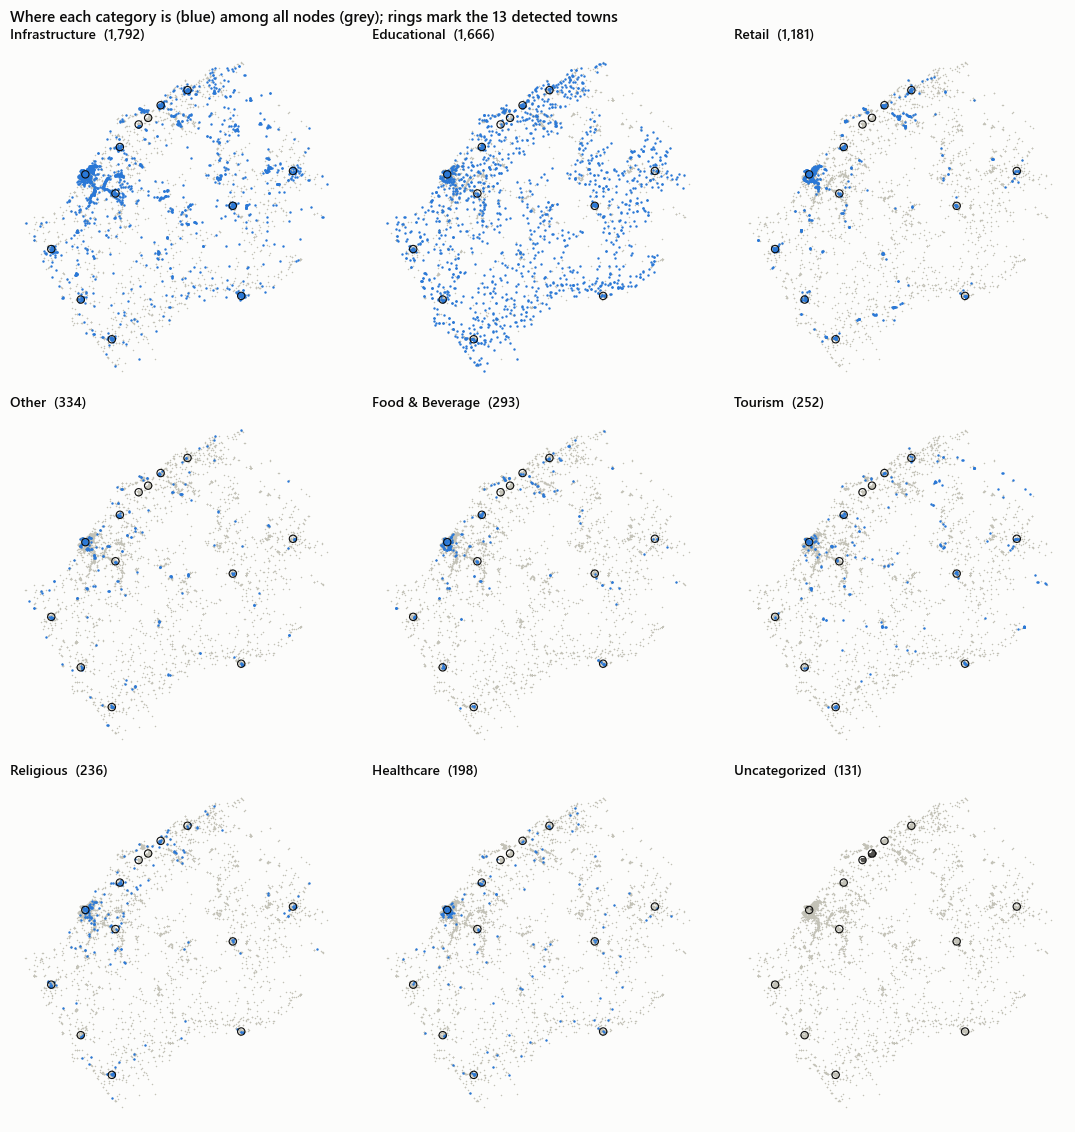

In [17]:
print(f"Nodes sharing an exact position with another node: {(poi['nn1_dist_m'] == 0).sum()}\n")
print("Median distance to the nearest town (km) and share of nodes in towns, by category:")
print(poi.groupby("category").agg(median_dist_town_km=("dist_town_km", "median"), urban_pct=("is_urban", "mean"),
                                  median_density_2km=("density_2km", "median"), median_latrines_1km=("latrines_1km", "median"))
      .loc[CATS + ["Uncategorized"]].assign(urban_pct=lambda d: (d["urban_pct"] * 100).round(0)).round(1).to_string())

lon0, lat0 = 29.5, -29.5
fig, axes = plt.subplots(3, 3, figsize=(11, 11.5))
geo_x = poi["x_km"]; geo_y = poi["y_km"]
for ax, cat in zip(axes.ravel(), CATS + ["Uncategorized"]):
    m = poi["category"].eq(cat)
    ax.scatter(geo_x[~m], geo_y[~m], s=1.2, c=AXIS, lw=0)
    ax.scatter(geo_x[m], geo_y[m], s=3, c=BLUE if cat != "Uncategorized" else INK2, lw=0)
    ax.scatter(towns["x"] / 1000, towns["y"] / 1000, s=28, facecolors="none", edgecolors=INK, lw=.8)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(f"{cat}  ({m.sum():,})", fontsize=10)
fig.suptitle("Where each category is (blue) among all nodes (grey); rings mark the 13 detected towns",
             x=0.02, ha="left", fontsize=11, fontweight="semibold")
plt.tight_layout(); plt.show()

**Findings.** The data-derived towns match Lesotho's ten district towns plus Roma (Manonyane) and two Berea/Leribe
settlements. Categories differ sharply in where they sit: 70% of Retail and 62% of Food & Beverage nodes are urban
(median 2.4 km and 3.6 km from a town centre), while schools are spread through the villages (15% urban, 15.6 km) and
Tourism sits in the highlands (12.6 km). Location features alone should therefore separate commercial from
non-commercial types; the harder task is separating the town-centre types from each other, which is where neighbours
help. `latrines_1km` is zero for most nodes: it is informative mainly where latrines were mapped (Mafeteng).

### Business landscape by district
The business subset (retail, food and drink, accommodation, finance, services) is what the location recommendations
are about. Schools are the one type mapped almost everywhere people live, so businesses per school gives a rough,
data-internal sense of how commercial each district's mapped landscape is.

               business_nodes  schools  business_in_towns_% most_common_business  businesses_per_10_schools
adm1_name                                                                                                  
Maseru                    762      297                 83.0    Automotive & fuel                       25.7
Berea                     273      136                 83.0    Automotive & fuel                       20.1
Mafeteng                  123      104                 63.0        Small grocery                       11.8
Leribe                    220      210                 23.0        Small grocery                       10.5
Butha-Buthe                74       94                 47.0        Accommodation                        7.9
Quthing                    86      146                 38.0        Small grocery                        5.9
Qacha's Nek                58      125                 84.0        Accommodation                        4.6
Mokhotlong                 5

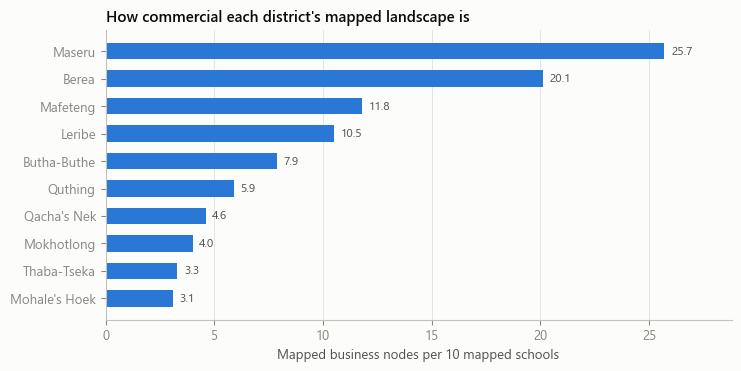

In [18]:
is_biz = poi["subcategory"].isin(BUSINESS_SUBS)
biz = poi[is_biz]
land = pd.DataFrame({
    "business_nodes": biz.groupby("adm1_name").size(),
    "schools": poi[poi["subcategory"].eq("School")].groupby("adm1_name").size(),
    "business_in_towns_%": (biz.groupby("adm1_name")["is_urban"].mean() * 100).round(0),
    "most_common_business": biz.groupby("adm1_name")["subcategory"].agg(lambda s: s.value_counts().index[0]),
})
land["businesses_per_10_schools"] = (land["business_nodes"] / land["schools"] * 10).round(1)
land = land.sort_values("businesses_per_10_schools", ascending=False)
print(land.to_string(), "\n")
maseru_town = biz["nearest_town"].eq(towns.iloc[0]["town_sub_district"]) & biz["is_urban"].eq(1)
print(f"Business nodes: {len(biz):,}; {maseru_town.mean():.0%} of them are in Maseru town, "
      f"{biz['is_urban'].mean():.0%} in any town\n")

urb = (biz.groupby("subcategory")["is_urban"].agg(["size", "mean"])
       .rename(columns={"size": "nodes", "mean": "urban_share"}).sort_values("urban_share"))
print("Most rural business types:", ", ".join(f"{s} ({v:.0%} urban)" for s, v in urb["urban_share"].head(4).items()))
print("Most urban business types:", ", ".join(f"{s} ({v:.0%} urban)" for s, v in urb["urban_share"].tail(4).items()))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
s = land["businesses_per_10_schools"].sort_values()
ax.barh(s.index, s.values, color=BLUE, height=.6)
for y, v in enumerate(s.values):
    ax.text(v + .3, y, f"{v:.1f}", va="center", color=INK2, fontsize=8.5)
ax.set_xlim(0, s.max() * 1.12); ax.grid(axis="y", visible=False)
ax.set_xlabel("Mapped business nodes per 10 mapped schools")
ax.set_title("How commercial each district's mapped landscape is")
plt.tight_layout(); plt.show()

**Findings.** The mapped business landscape is concentrated: 41% of the 1,756 business nodes are in Maseru town and
66% are in some town. Maseru and Berea have 20 to 26 businesses per 10 schools; the highland districts (Mokhotlong,
Thaba-Tseka, Qacha's Nek) and Mohale's Hoek have 3 to 5, and there accommodation is the most common business. Clothing,
fast food, hardware and phone shops are almost entirely urban (88 to 95%); accommodation, restaurants and funeral
services are the types most often found outside towns. Part of this gap is mapping effort rather than economy, which is
why the model must be judged on held-out areas.

## 9. Spatial cross-validation folds

Random train/test splits put a test node next to training nodes of the same category (Section 6: dependence lasts to
about 700 m), which overstates accuracy. Instead, square blocks are assigned whole to one of 5 folds. The block must be
much wider than 700 m, but blocks that are too large leave the folds unbalanced (Maseru alone holds 1,407 urban nodes).
Assignment: 500 random block orders, each filled greedily into the fold with the fewest labelled nodes; keep the order
whose per-class fold shares are most even.

In [19]:
N_FOLDS, DEP_RANGE_M = 5, 700
cls_codes = pd.Categorical(poi["category"].where(labelled), categories=CATS).codes  # -1 for Uncategorized

def assign_folds(block_km, n_tries=500, seed=SEED):
    bid = (np.floor(poi["x"] / (block_km * 1000)).astype(int).astype(str) + "_" +
           np.floor(poi["y"] / (block_km * 1000)).astype(int).astype(str)).to_numpy()
    blocks, inv = np.unique(bid, return_inverse=True)
    counts = np.zeros((len(blocks), len(CATS)))
    np.add.at(counts, (inv[cls_codes >= 0], cls_codes[cls_codes >= 0]), 1)
    rng, best = np.random.default_rng(seed), (np.inf, None)
    for _ in range(n_tries):
        order = rng.permutation(len(blocks))
        fold_of, load = np.empty(len(blocks), int), np.zeros((N_FOLDS, len(CATS)))
        for bk in order:
            f = load.sum(1).argmin(); fold_of[bk] = f; load[f] += counts[bk]
        share = load / load.sum(0)
        score = np.abs(share - 1 / N_FOLDS).max()
        if score < best[0]:
            best = (score, fold_of.copy())
    return best[1][inv], bid, len(blocks), best[0]

def leak_share(fold):
    """Share of nodes with a node from another fold within DEP_RANGE_M."""
    nb = tree.query_ball_point(XY, DEP_RANGE_M)
    return np.mean([any(fold[j] != fold[i] for j in js) for i, js in enumerate(nb)])

rows, fold_opts = [], {}
for bk in [5, 10]:
    fold, bid, nblocks, worst = assign_folds(bk)
    fold_opts[bk] = (fold, bid)
    sizes_ = pd.Series(fold).value_counts()
    largest_block = pd.Series(bid).value_counts().max()
    rows.append((bk, nblocks, largest_block, sizes_.min(), sizes_.max(), worst * 100, leak_share(fold) * 100))
print(pd.DataFrame(rows, columns=["block_km", "blocks", "largest_block_nodes", "smallest_fold", "largest_fold",
                                  "worst_class_share_dev_pp", "nodes_with_other_fold_within_700m_%"])
      .round(1).to_string(index=False))

 block_km  blocks  largest_block_nodes  smallest_fold  largest_fold  worst_class_share_dev_pp  nodes_with_other_fold_within_700m_%
        5     840                  695           1182          1297                       6.3                                 15.3
       10     298                 1054           1180          1306                      16.9                                  6.3


**Decision: 5 km blocks.** They keep every class within 6.3 percentage points of an even 20% per fold; 10 km blocks
put up to 37% of a class into one fold, which makes per-fold macro-F1 unstable for the small classes. The cost is that
15% of nodes have a node from another fold within 700 m. Those nodes are flagged (`fold_boundary`), so the model can
leave them out of the training loss (a buffered spatial CV) when the neighbouring fold is the test fold.

                 fold 0  fold 1  fold 2  fold 3  fold 4
category                                               
Infrastructure      362     367     349     354     360
Educational         353     341     339     389     244
Retail              191     232     251     217     290
Other                63      61      70      60      80
Food & Beverage      67      66      40      48      72
Tourism              59      45      47      55      46
Religious            42      47      57      53      37
Healthcare           45      39      30      32      52
Uncategorized         0      14       0       1     116
All nodes          1182    1212    1183    1209    1297 

Boundary nodes per fold: {0: 192, 1: 280, 2: 101, 3: 217, 4: 138}


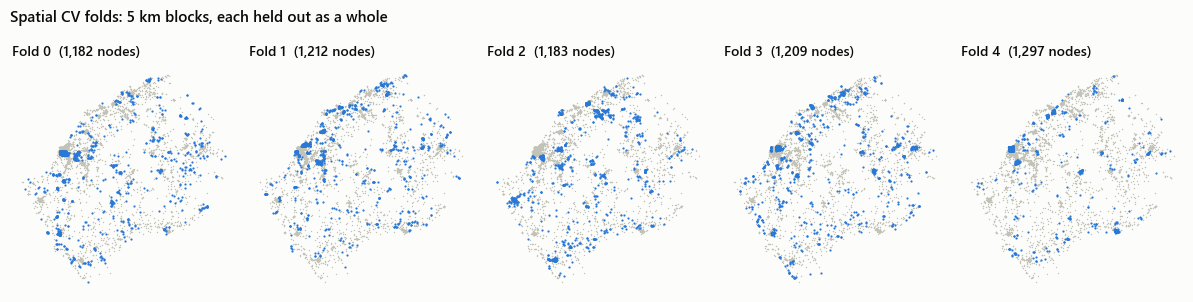

In [20]:
BLOCK_KM = 5
poi["fold"], poi["block_id"] = fold_opts[BLOCK_KM]
nb700 = tree.query_ball_point(XY, DEP_RANGE_M)
fv = poi["fold"].to_numpy()
poi["fold_boundary"] = [int(any(fv[j] != fv[i] for j in js)) for i, js in enumerate(nb700)]

ft = pd.crosstab(poi["category"], poi["fold"]).loc[CATS + ["Uncategorized"]]
ft.loc["All nodes"] = ft.sum()
ft.columns = [f"fold {c}" for c in ft.columns]
print(ft.to_string(), "\n")
print("Boundary nodes per fold:", poi.groupby("fold")["fold_boundary"].sum().to_dict())

fig, axes = plt.subplots(1, N_FOLDS, figsize=(12, 3.2))
for f, ax in enumerate(axes):
    m = poi["fold"].eq(f)
    ax.scatter(poi.loc[~m, "x_km"], poi.loc[~m, "y_km"], s=1, c=AXIS, lw=0)
    ax.scatter(poi.loc[m, "x_km"], poi.loc[m, "y_km"], s=2.5, c=BLUE, lw=0)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(f"Fold {f}  ({m.sum():,} nodes)", fontsize=10)
fig.suptitle("Spatial CV folds: 5 km blocks, each held out as a whole", x=0.01, ha="left",
             fontsize=11, fontweight="semibold")
plt.tight_layout(); plt.show()

## 10. Export `processed_poi.csv`

One row per node. Each column has a role: `id` and `info` columns are for joining and reading results; `label` columns
are targets; `feature_loc` columns can be computed for any site; `feature_attr` columns exist only for mapped POIs;
`graph` columns are used to build administrative edges; `split` columns define cross-validation. Features are left
unscaled so that scaling can be fitted on training folds.

In [21]:
LABEL_MAP = {c: i for i, c in enumerate(CATS)}  # Uncategorized -> -1
poi["node_id"] = np.arange(len(poi))
poi["osm_id"] = poi["id"]
lonlat = gpd.GeoSeries(gpd.points_from_xy(poi["x"], poi["y"]), crs=CRS_M).to_crs(CRS_GEO)
poi["lon"], poi["lat"] = lonlat.x.round(7), lonlat.y.round(7)
poi["label"] = poi["category"].map(LABEL_MAP).fillna(-1).astype(int)
poi["is_labelled"] = labelled.astype(int).to_numpy()
poi["is_business"] = poi["subcategory"].isin(BUSINESS_SUBS).astype(int)
poi["adm1_idx"] = poi["adm1_pcode"].astype("category").cat.codes
poi["adm2_idx"] = poi["adm2_pcode"].astype("category").cat.codes

COLUMNS = {
    "node_id": ("id", "Row index 0..N-1; use as the graph node index"),
    "osm_id": ("id", "OSM id of the representative feature (node/123 or way/456)"),
    "osm_ids": ("info", "All OSM ids merged into this node, ';'-separated"),
    "n_units": ("info", "Features merged into this node. Computed from labels: NOT a feature"),
    "name": ("info", "Name. Leaks the label (66% contain a category keyword): NOT a feature"),
    "tag_key": ("info", "OSM key the label came from. Source of the label: NOT a feature"),
    "tag_value": ("info", "OSM value the label came from. Source of the label: NOT a feature"),
    "lon": ("info", "Longitude, WGS84"),
    "lat": ("info", "Latitude, WGS84"),
    "nearest_town": ("info", "Sub-district name of the nearest data-derived town"),
    "category": ("label", "One of 8 categories, or Uncategorized"),
    "label": ("label", "Integer target 0-7; -1 = unlabelled (Uncategorized)"),
    "is_labelled": ("label", "1 if label >= 0"),
    "subcategory": ("label", "Finer type (36 values); possible secondary target"),
    "is_business": ("label", "1 for private-business subcategories (retail, food, accommodation, finance, services)"),
    **{c: ("feature_loc", d) for c, d in [
        ("x_km", "UTM 35S easting, km"), ("y_km", "UTM 35S northing, km"),
        ("dist_town_km", "Distance to the nearest data-derived town centre"),
        ("dist_maseru_km", "Distance to the Maseru town centre"),
        ("is_urban", f"1 if >= {TOWN_MIN_POIS} other nodes within {TOWN_RADIUS_M} m"),
        ("density_500m", "Other nodes within 500 m"), ("density_2km", "Other nodes within 2 km"),
        ("density_10km", "Other nodes within 10 km"),
        ("nn1_dist_m", "Distance to the nearest other node"),
        ("knn8_mean_dist_m", "Mean distance to the 8 nearest nodes"),
        ("latrines_1km", "Household latrines (removed toilet features) within 1 km; mapping-biased to Mafeteng")]},
    **{c: ("feature_attr", d) for c, d in [
        ("has_name", "1 if named"), ("has_address", "1 if any address field"), ("has_hours", "1 if opening hours"),
        ("has_footprint", "1 if mapped with a building outline"),
        ("log_footprint_m2", "log(1 + largest outline area in m2); 0 when has_footprint = 0"),
        ("is_point", "1 if mapped (also) as a point"),
        ("quality_score", "Mean of has_name, has_address, has_hours, has_footprint"),
        ("osm_id_rank", "Percentile of the OSM id (proxy for mapping date); bias covariate")]},
    "adm1_pcode": ("graph", "District code (10)"), "adm1_name": ("graph", "District name"),
    "adm2_pcode": ("graph", "Sub-district code (78)"), "adm2_name": ("graph", "Sub-district name"),
    "adm1_idx": ("graph", "District index 0-9"), "adm2_idx": ("graph", "Sub-district index 0-77"),
    "fold": ("split", f"Spatial CV fold 0-{N_FOLDS - 1} ({BLOCK_KM} km blocks)"),
    "block_id": ("split", f"{BLOCK_KM} km block the node falls in"),
    "fold_boundary": ("split", f"1 if a node of another fold lies within {DEP_RANGE_M} m"),
}
out = poi[list(COLUMNS)].copy()
out.to_csv(OUT_CSV, index=False, encoding="utf-8")

data_dictionary = pd.DataFrame([(c, r, d) for c, (r, d) in COLUMNS.items()], columns=["column", "role", "description"])
print(f"Wrote {OUT_CSV}: {out.shape[0]:,} rows x {out.shape[1]} columns\n")
print(data_dictionary.to_string(index=False))

Wrote processed_poi.csv: 6,083 rows x 43 columns

          column         role                                                                           description
         node_id           id                                         Row index 0..N-1; use as the graph node index
          osm_id           id                            OSM id of the representative feature (node/123 or way/456)
         osm_ids         info                                      All OSM ids merged into this node, ';'-separated
         n_units         info                   Features merged into this node. Computed from labels: NOT a feature
            name         info                 Name. Leaks the label (66% contain a category keyword): NOT a feature
         tag_key         info                       OSM key the label came from. Source of the label: NOT a feature
       tag_value         info                     OSM value the label came from. Source of the label: NOT a feature
             lon      

In [22]:
chk = pd.read_csv(OUT_CSV, keep_default_na=False, na_values=[""])
role = data_dictionary.set_index("column")["role"]
must_be_complete = role[role.isin(["id", "label", "feature_loc", "feature_attr", "graph", "split"])].index
FEATURES = role[role.str.startswith("feature")].index.tolist()

assert len(chk) == len(poi) and chk["node_id"].tolist() == list(range(len(chk)))
assert chk["osm_id"].is_unique
assert chk[must_be_complete].isna().sum().sum() == 0, chk[must_be_complete].isna().sum().loc[lambda s: s > 0]
assert chk["label"].between(-1, 7).all() and (chk["label"].eq(-1) == chk["category"].eq("Uncategorized")).all()
assert (chk["subcategory"].map(SUB_TO_CAT) == chk["category"]).all()
assert chk["fold"].between(0, N_FOLDS - 1).all()
assert chk["lon"].between(27.0, 29.5).all() and chk["lat"].between(-30.7, -28.5).all()
assert np.isfinite(chk[FEATURES].to_numpy(float)).all()
print(f"All checks passed: {len(chk):,} nodes, {chk['is_labelled'].sum():,} labelled, {len(FEATURES)} features, "
      f"{chk['adm1_pcode'].nunique()} districts, {chk['adm2_pcode'].nunique()} sub-districts")
print("Nodes sharing an exact position:", chk.loc[chk["nn1_dist_m"] == 0, ["node_id", "tag_value", "category"]]
      .to_dict("records"), "-> drop self-loops explicitly when building k-NN edges")

All checks passed: 6,083 nodes, 5,952 labelled, 19 features, 10 districts, 78 sub-districts
Nodes sharing an exact position: [{'node_id': 4469, 'tag_value': 'atm', 'category': 'Other'}, {'node_id': 5031, 'tag_value': 'convenience', 'category': 'Retail'}] -> drop self-loops explicitly when building k-NN edges


## 11. Summary

**Cleaning.** 12,536 raw features → **6,083 nodes** in `processed_poi.csv` (5,952 labelled, 131 unlabelled):
2 placeholders and 162 linear network features dropped; 4,473 household latrines moved into the `latrines_1km`
feature; 1,816 duplicates and repeated units merged (same place as point + outline, points inside outlines, and
unnamed same-type units within 50 m).

**What the EDA means for the GNN**

| Design question | Evidence | Implication |
|---|---|---|
| Target | 8 categories, largest 9.1× the smallest | Class-weighted loss (weights in Section 4), macro-F1 and per-class recall |
| Spatial edges | k = 8 is the smallest k tested that connects all nodes; median edge 0.84 km | k-NN with k = 8; drop self-loops explicitly (two nodes share a position) |
| Administrative edges | All 10 districts and 78 sub-districts present | Build from `adm2_pcode` / `adm1_pcode` |
| Thematic edges | Retail–Food & Beverage, Retail–Other, Other–Healthcare, Tourism–Food & Beverage attract (CLQ 1.3–1.8) | Recompute CLQs on each training fold only |
| Is there graph signal? | 39% of k-NN edges join same-category nodes vs 22% by chance; fades by ~700 m | Yes, but local; Healthcare barely clusters with itself, which favours GraphSAGE/GAT over plain GCN |
| Features | 11 location features (any site) + 8 attribute features (mapped POIs only) | Scale inside each training fold; never use `name`, tags or `n_units` |
| Evaluation | Random splits would put test nodes beside same-type training nodes | Spatial CV with 5 km blocks (`fold`); optional 700 m buffer via `fold_boundary` |
| Bias | Mafeteng latrine campaign; Maseru mapped later; 41% of businesses in Maseru town | Check results per district and against `osm_id_rank` |

**Figures in the proposal to update:** 7,529 processed POIs → 6,083 nodes; 1,471 Uncategorized → 131; "median
neighbour distance 2 to 3 km" → 121 m to the nearest POI and 839 m to the 8th nearest; class weights as in Section 4.